# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución
## GRUPO: Ax=b

# Integrantes
* Jano Bayarsky
* Ivan Flores

In [17]:
%cd /content

# Descargamos el repositorio o actualizamos la copia existente
!if [ -d Reentrega_TP_ALC/.git ]; then git -C Reentrega_TP_ALC pull --ff-only; else git clone https://github.com/janobayarsky/Reentrega_TP_ALC.git; fi

%cd /content/Reentrega_TP_ALC

/content
Already up to date.
/content/Reentrega_TP_ALC


Importamos los módulos que vamos a utilizar:

In [ ]:
from matplotlib import pyplot as plt
import cv2
import numpy as np
from alc import *
import pandas as pd

# Ejercicios:

### Ejercicio 1 - DLT ecuaciones formales

- Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

**Respuesta:**

Se busca resolver el sistema $Qm=0$.

Como $Q\in \mathbb{R}^{2n\times 12}$, necesitamos que $12 = \dim\operatorname{Nu}(Q) + \operatorname{rango}(Q)$ (por teorema de la dimensión).
Como se quiere que las soluciones estén a menos de un factor de escala, se pide que $\dim\operatorname{Nu}(Q) = 1$.
Despejando, se obtiene que el rango de $Q$ debe ser $11$.

Para tener un rango $11$, se requiere que la cantidad de puntos sea al menos $6$, ya que cada punto puede aportar a lo sumo dos al rango, y como $n\ge 6 \Rightarrow 2n\ge 12 \ge 11$.

Supongamos que existe un plano $ax+by+cz-d=0$ que contiene a todos los puntos. Entonces existe $v=(a,b,c,-d)\neq0$ tal que $v^\top P_i=0$ para todo $i$ (evaluar cada punto en la ecuación del plano la verifica). Por lo tanto, los vectores $(v,0,0)$ y $(0,v,0)$ de $\mathbb{R}^{12}$ cumplen $Qm=0$ y están en el núcleo de $Q$, con lo que $\dim\operatorname{Nu}(Q)>1$. Entonces los puntos no deben ser coplanares.

Los puntos de un mismo plano aportan en total a lo sumo $8$ al rango de $Q$, sin importar cuántos sean (los primeros $4$ aportan $2$ cada uno y los siguientes nada). Cada punto fuera de ese plano aporta a lo sumo $2$. Para llegar a rango $11$ hacen falta entonces al menos $2$ puntos fuera del plano, ya que $8+2=10<11$ pero $8+2+2=12\ge 11$. Por lo tanto, con $6$ puntos, a lo sumo $4$ pueden estar en un mismo plano.

- Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

**Respuesta:**

Queremos minimizar $\|Qm\|_2^2$, sujeto a $\|m\|_2 = 1$.

Calculo la SVD de $Q = U \Sigma V^\top$. Entonces $\|Qm\|_2^2 = \|U \Sigma V^\top m\|_2^2$. Como $U$ es ortogonal, esto es igual a $\|\Sigma V^\top m\|_2^2$. Renombrando al vector $V^\top m = y$, se tiene $\|\Sigma y\|_2^2$, y el vector $\Sigma y$ es igual a $(\sigma_1 y_1, \sigma_2 y_2, \dots, \sigma_{12} y_{12})$. Entonces

$$\|\Sigma y\|_2^2 = (\sigma_1 y_1)^2 + \dots + (\sigma_{12} y_{12})^2.$$

Cada $\sigma_i$ es mayor o igual que $\sigma_{12}$, así que esa suma es mayor o igual que

$$\sigma_{12}^2 \,(y_1^2 + y_2^2 + \dots + y_{12}^2) = \sigma_{12}^2 \|y\|_2^2.$$

Como $y = V^\top m$ y $V$ es ortogonal, $\|y\|_2^2 = \|m\|_2^2 = 1$ (lo pedimos antes de calcularlo). Recapitulando, llegamos a que

$$\|Qm\|_2^2 \ge \sigma_{12}^2 .$$

Para ver que esa cota se alcanza, volvemos a que $\|Qm\|_2^2 = \|\Sigma y\|_2^2$. Si tomamos $y = (0,0,\dots,1)$, entonces $\|\Sigma y\|_2^2 = \|(0,0,\dots,\sigma_{12})\|_2^2 = \sigma_{12}^2$. Recuperando la información original, $y = e_{12} = V^\top m$. Como $V^\top$ es ortogonal, $m = V e_{12}$, que es igual a tomar la última columna de $V$.

En conclusión, para hallar $m$, solamente basta con elegir la última columna de $V$, de la SVD de $Q$.

### Ejercicio 2 - Calibración con puntos 3D

Ejercicio de calibración de puntos 3D:

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para

b) $\alpha_u = \alpha_v$

c) $K_{12}=0$

Resolución:

In [ ]:
#a)
det_corners = np.loadtxt('Archivos/calib/3d/detected_corners.txt')
u = det_corners[:,0::2]
v = det_corners[:,1::2]

real_corners = np.loadtxt('Archivos/calib/3d/p_W_corners.txt',delimiter=',')
Xw, Yw, Zw = real_corners[:,0], real_corners[:,1],real_corners[:,2]

k = 0
objPts = real_corners.copy()
imgPts = np.column_stack((u[k], v[k]))  # (12, 2): píxeles (u, v) de la imagen k

Q1 = obtenerQ3d(imgPts,objPts)
M1 = resolverDLT3D(Q1)
R,t,K = devolverMatricesCalibracion3d(M1,misma_focal=False,sin_skew=False)

#b
R_misma_focal,t_misma_focal,K_misma_focal = devolverMatricesCalibracion3d(M1,misma_focal=True,sin_skew=False)

#c
R_sin_skew,t_sin_skew,K_sin_skew = devolverMatricesCalibracion3d(M1,misma_focal=False,sin_skew=True)

#b y c
R_misma_focal_sin_skew,t_misma_focal_sin_skew,K_misma_focal_sin_skew = devolverMatricesCalibracion3d(M1,misma_focal=True,sin_skew=True)

In [ ]:
np.set_printoptions(precision=4, suppress=True)

resultados = [
    ("a) Sin restricciones", K, R, t),
    ("b) Misma focal (au = av)", K_misma_focal, R_misma_focal, t_misma_focal),
    ("c) Sin sesgo (K12 = 0)", K_sin_skew, R_sin_skew, t_sin_skew),
    ("b y c) Misma focal y sin sesgo", K_misma_focal_sin_skew, R_misma_focal_sin_skew, t_misma_focal_sin_skew),
]

print("Imagen 0001 (k = 0)\n")

for titulo, K_i, R_i, t_i in resultados:
    print(f"{titulo}")
    print("K:\n", K_i)
    print("R:\n", R_i)
    print("t:\n", t_i.reshape(-1), "\n")

Imagen 0001 (k = 0)

a) Sin restricciones
K:
 [[425.8599  -0.0156 354.4185]
 [  0.     424.5653 256.8534]
 [  0.       0.       1.    ]]
R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t:
 [-18.1679 -14.5033  40.5913] 

b) Misma focal (au = av)
K:
 [[425.2126  -0.0156 354.4185]
 [  0.     425.2126 256.8534]
 [  0.       0.       1.    ]]
R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t:
 [-18.1956 -14.4812  40.5913] 

c) Sin sesgo (K12 = 0)
K:
 [[425.8599   0.     354.4185]
 [  0.     424.5653 256.8534]
 [  0.       0.       1.    ]]
R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t:
 [-18.1674 -14.5033  40.5913] 

b y c) Misma focal y sin sesgo
K:
 [[425.2126   0.     354.4185]
 [  0.     425.2126 256.8534]
 [  0.       0.       1.    ]]
R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t:
 [-18.1951 -14.4812  40.5913] 



Reproyectamos los puntos, comparando los uv originales, de detected corners, con los obtenidos al multiplicar las distintas M por los puntos reales.

Como queremos transformar cada punto usando la matriz, ponemos a cada punto como columna, así que debemos tomar la matriz real_corners traspuesta.

In [ ]:
R,t,K = devolverMatricesCalibracion3d(M1,misma_focal=False,sin_skew=False)

#b
R_misma_focal,t_misma_focal,K_misma_focal = devolverMatricesCalibracion3d(M1,misma_focal=True,sin_skew=False)

#c
R_sin_skew,t_sin_skew,K_sin_skew = devolverMatricesCalibracion3d(M1,misma_focal=False,sin_skew=True)

#b y c
R_misma_focal_sin_skew,t_misma_focal_sin_skew,K_misma_focal_sin_skew = devolverMatricesCalibracion3d(M1,misma_focal=True,sin_skew=True)

In [ ]:
real_corners_con_unos = np.column_stack((real_corners, np.ones(12))).T

uv = obtener_uv_con_M(K,R,t,real_corners_con_unos)
uv_misma_focal = obtener_uv_con_M(K_misma_focal,R_misma_focal,t_misma_focal,real_corners_con_unos)
uv_sin_skew = obtener_uv_con_M(K_sin_skew,R_sin_skew,t_sin_skew,real_corners_con_unos)
uv_misma_focal_sin_skew = obtener_uv_con_M(K_misma_focal_sin_skew,R_misma_focal_sin_skew,t_misma_focal_sin_skew,real_corners_con_unos)

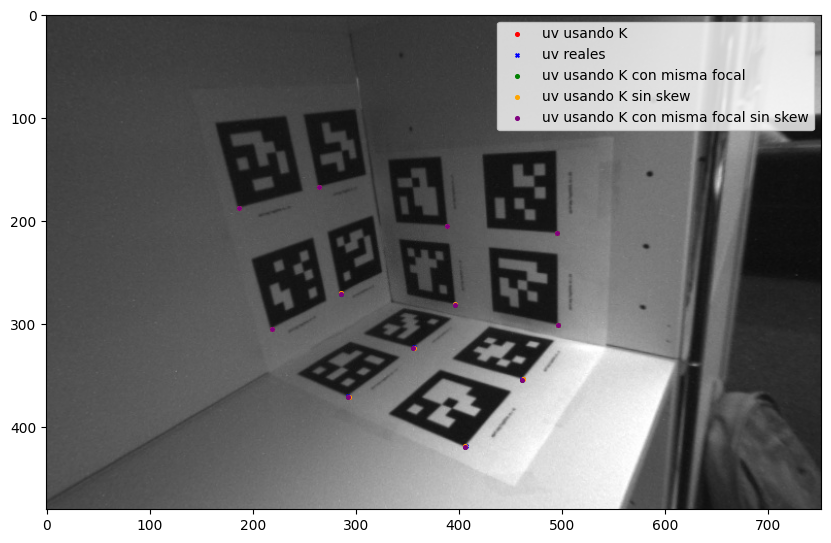

In [ ]:
toma_1_3d = cv2.imread('Archivos/calib/3d/img_0001.jpg')
toma_1_3d = cv2.cvtColor(toma_1_3d, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(toma_1_3d)

plt.scatter(uv[:,0],uv[:,1], color="red", zorder=5,s=7,label='uv usando K')
plt.scatter(u[0,:],v[0,:], color="blue", s=7, zorder=5, marker='x',label='uv reales')
plt.scatter(uv_misma_focal[:,0],uv_misma_focal[:,1], color="green", zorder=5,s=7,label='uv usando K con misma focal')
plt.scatter(uv_sin_skew[:,0],uv_sin_skew[:,1], color="orange", zorder=5,s=7,label='uv usando K sin skew')
plt.scatter(uv_misma_focal_sin_skew[:,0],uv_misma_focal_sin_skew[:,1], color="purple", zorder=5,s=7,label='uv usando K con misma focal sin skew')

plt.legend()
plt.show()

No se llegan a apreciar las diferencias, pero si se ejecuta cada color por separado se ve que todos corresponden a las esquinas.

Los cálculos de K, R y t parecen buenos, vamos a comprobar si es asi.

In [ ]:

for nombre, uv_i in [("a) original", uv), ("b) misma focal", uv_misma_focal),
                     ("c) sin skew", uv_sin_skew), ("b y c", uv_misma_focal_sin_skew)]:
    media, maximo = error_reproy(uv_i, u[0,:], v[0,:])
    print(f"{nombre}: error medio {media:.3f} px, máximo {maximo:.3f} px")

a) original: error medio 0.331 px, máximo 0.745 px
b) misma focal: error medio 0.476 px, máximo 1.008 px
c) sin skew: error medio 0.331 px, máximo 0.749 px
b y c: error medio 0.476 px, máximo 1.010 px


In [ ]:
print("Alfa u: ",K[0][0])
print("Alfa v: ",K[1][1])
print("Skew: ",K[0][1])

Alfa u:  425.85986255348155
Alfa v:  424.56530709841195
Skew:  -0.015635209388132752


Sin restricciones, la calibración da αu = 425.86, αv = 424.57 y K12 = -0.016.
El skew estimado es prácticamente nulo (0.004 % de αu), por lo que imponer
K12 = 0 casi no modifica el error de reproyección (a y c dan prácticamente
lo mismo). Las focales difieren en 1.29 px (~0.3 %); forzar αu = αv
(f = 425.21) aumenta el error medio de 0.331 a 0.473 px (+43 % relativo,
+0.14 px absolutos). Como se ve en la figura, los cuatro conjuntos de puntos se superponen con las esquinas reales.
Imponer ambas restricciones da un resultado
similar al de b). Estos resultados corresponden a la imagen 0001.

### Ejercicio 3 - Calibración con puntos coplanares

Ejercicio de calibración de puntos coplanares:

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.

a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

Resolución:

a)

Vamos a realizar una calibración de puntos coplanares para verificar que las funciones implementadas hagan lo esperado. Tomando 20 imagenes de un tablero de ajedrez, visto desde distíntos ángulos, queremos determinar los parámetros de la cámara y de las distintas poses.

Las esquinas internas del tablero tienen coordenadas (30 i, 30 j) mm, con i = 0,...,10 y j = 0,...,6.
Determinamos que la esquina superior interna izquierda tiene coordenadas (30x0,30x0)mm = (0,0)mm. L esquina inferior interna derecha (30x10,30x6)mm = (300,180)mm.

Para construir la matriz Q, $Q\in \mathbb{R}^{2n\times 9}$, por el teorema de la dimensión, pedimos que Dim(Nu(Q)) + Rango(Q) = 9. Como queremos que tenga solución única a menos de un factor de escala, el núcleo debe tener dimensión 1.

Por lo tanto, Rango(Q) = 9 - 1 = 8. Como vimos en la calibración de puntos 3D, cada punto suma dos al rango. Como se busca que el rango sea 8, se necesitan 4 puntos para poder realizar la calibración.

Como sabemos que con 4 puntos nos alcanza para obtener la matriz Hj de cada toma, seleccionamos las 4 esquinas más externas del tablero de todas las tomas. Seleccionamos los puntos con paint y los registramos en un Excel.

In [ ]:
puntos_imagen_calib_cop = pd.read_excel("puntos_tablero_calibracion_coplanares.xlsx", skiprows=2, header=None, usecols="B:I").to_numpy()
puntos_imagen_calib_cop.shape

(20, 8)

In [ ]:
u_cop = puntos_imagen_calib_cop[:,0::2]
v_cop = puntos_imagen_calib_cop[:,1::2]

pts_tablero = np.array([
    [0, 0], # Esquina superior izquierda
    [300, 0], # Esquina superior derecha
    [0, 180], # Esquina infeior izquierda
    [300, 180]  # Esquina inferior derecha
], dtype=float)
# Las columnas representan las coordenadas U, V

In [ ]:
Hlist = []
for j in range(20):
    objPts = pts_tablero.copy()
    imgPts = np.column_stack((u_cop[j], v_cop[j]))
    Qj = obtenerQ2d(imgPts,objPts)
    Hj = resolver2D(Qj)
    Hlist.append(Hj)

Hlist tiene una lista con los indices j=0 a 19, en los que cada posición devuelve la matriz de la imagen j+1 (j=19 corresponde a la imagen 20)

In [18]:
A = armarA(Hlist)
K = calcularMatrizK2D(A)
K

ValueError: B no es definida positiva: revisar homografías / cantidad de vistas

# Creo que tenemos un problema de condicionamiento, si no me equivoco hay que usar Normalización isotrópica (página 14 apunte)

b)

Ahora falta hallar la pose de las imágenes 1,10 y 20

In [ ]:
R1,t1 = obtenerPose2D(Hlist[0], K)
R10,t10 = obtenerPose2D(Hlist[9], K)
R20,t20 = obtenerPose2D(Hlist[19], K)

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo.
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

Calculamos la distancia de Enzo al arco en el momento de patear:

In [20]:
img = cv2.imread("Archivos/futbol/test-gol-enzo.png")
if img is None:
    raise FileNotFoundError("No se pudo leer la imagen, revisá la ruta")

imgPts_enzo =  np.array([
            [510, 320],
            [651, 184],
            [383, 175],
            [842, 189],
            [196, 171],
            [865, 252],
            [156, 233]
        ])

objPts_enzo = np.array([[94,34],
                   [105,30.34],
                   [105,37.66],
                   [105,24.84],
                   [105,43.16],
                   [99.5,24.84],
                   [99.5,43.16]
                   ])

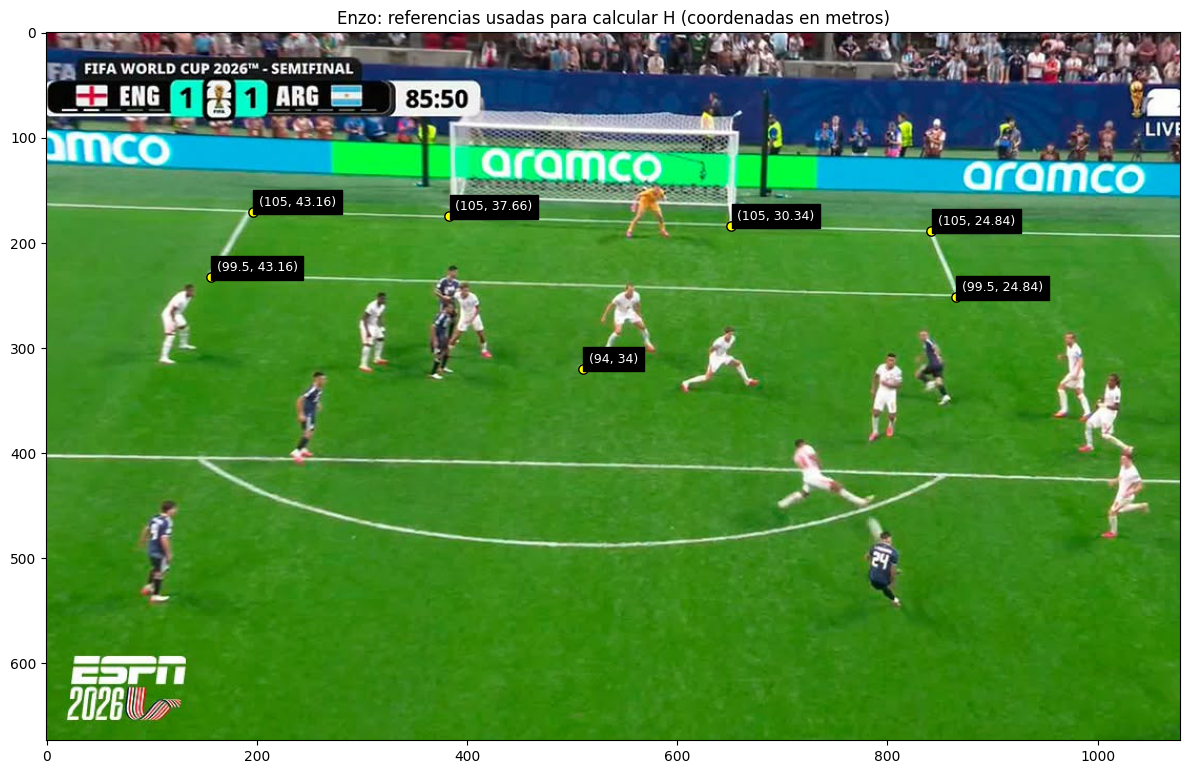

In [22]:
from matplotlib.image import imread

foto_enzo = imread("Archivos/futbol/test-gol-enzo.png")

plt.figure(figsize=(12, 8))
plt.imshow(foto_enzo)

for i in range(len(imgPts_enzo)):
    u, v = imgPts_enzo[i]
    x, y = objPts_enzo[i]

    plt.scatter(u, v, color="yellow", edgecolors="black", s=45)
    plt.text(u + 6, v - 6, f"({x:g}, {y:g})", color="white",
             fontsize=9, backgroundcolor="black")

plt.title("Enzo: referencias usadas para calcular H (coordenadas en metros)")
plt.tight_layout()
plt.show()

In [ ]:
Q = obtenerQ2d(imgPts,objPts)
H = resolver2D(Q)

pieEnzo = (807,540)

dist = distGolEnzo(pieEnzo,H)
print(dist)

23.0494930393196


Trazamos un círculo al rededor de los jugadores argentinos:

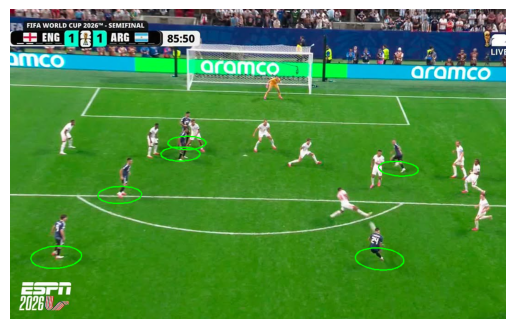

In [ ]:
#Ubicar jugadores argentinos
posJugadores = np.array([
    [101, 539],
    [239, 404],
    [371, 315],
    [385, 291],
    [804, 543],
    [845, 347]
])

H_inv = inversa(H)

img = cv2.imread("Archivos/futbol/test-gol-enzo.png")
assert img is not None, "no se encontró la imagen"


for pos in posJugadores:
    U,V = proyectar(H_inv,pos[0],pos[1])
    dibujar_circulo(img,H,U,V)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$.
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.

Para construir H necesitamos elegir al menos 4 puntos, de forma que ninguna de las filas de la matriz sea linealmente dependiente de las demás.

Elegimos 9 puntos con una separacion considerable entre sí. Los puntos reales de la cancha se eligieron tomando como referencia los datos del Estadio Azteca, y los puntos de la imagen los seleccionamos utilizando Paint, poniendo el cursor sobre el pixel buscado y registrando su valor.

En coordenadas reales, el area grande del lado derecho está en x=88,5; el area grande en x=99,5.
Desde el medio de la cancha (respecto a y), el arco tiene 3,66 mts para cada lado; 9,16 el área chica; y 20,16 el área grande.
La linea lateral superior está en y=0; la linea de fondo derecha en x=105.

In [24]:
puntos_cancha = np.array([
    [105,0],
    [105,(68/2)-(40.32/2)],
    [105,(68/2)-(18.32/2)],
    [105,(68/2)-(7.32/2)],
    [105-5.5,(68/2)-(18.32/2)],
    [105-5.5,(68/2)+(18.32/2)],
    [105-16.5,(68/2)-(40.32/2)],
    [105-16.5,(68/2)+(40.32/2)],

])

puntos_imagen = np.array([
    [1306, 235],
    [1388, 311],
    [1475, 387],
    [1524, 433],
    [1231, 391],
    [1365, 575],
    [735, 317],
    [736, 755],
])

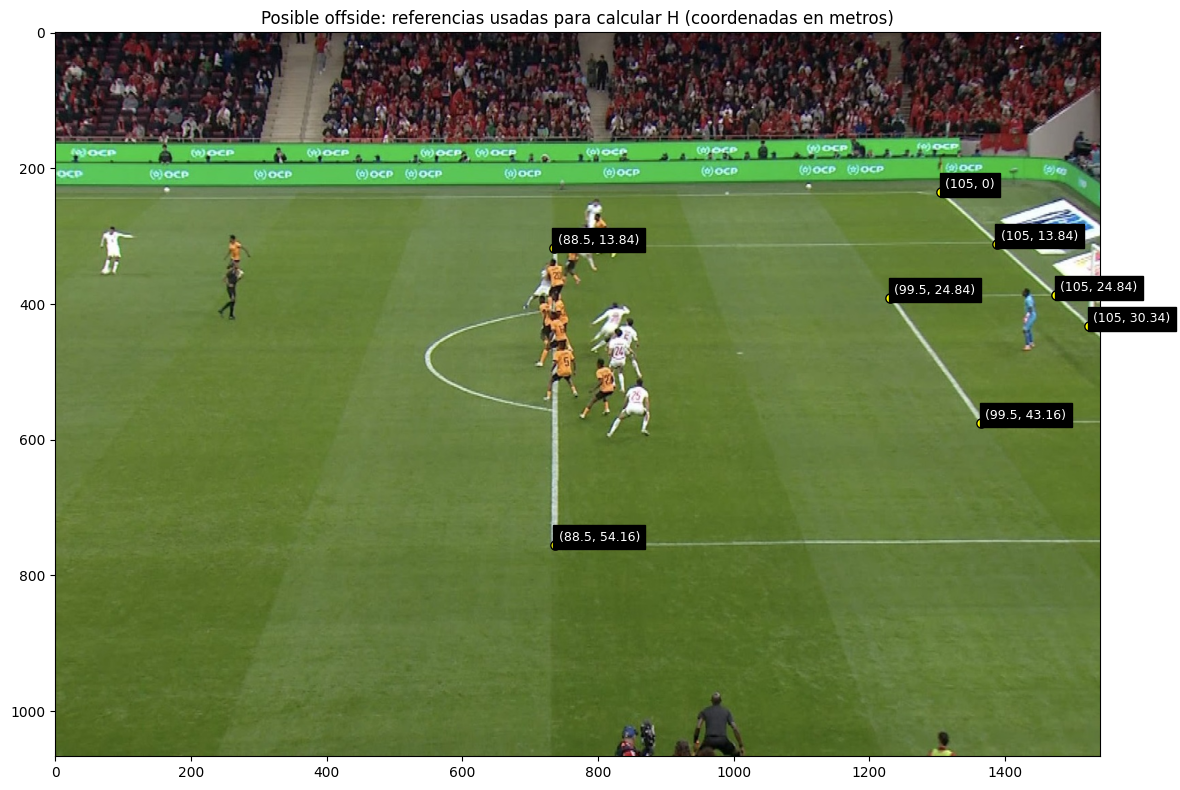

In [25]:
foto_offside = imread("Archivos/futbol/test-fuera-de-juego.png")

plt.figure(figsize=(12, 8))
plt.imshow(foto_offside)

for i in range(len(puntos_imagen)):
    u, v = puntos_imagen[i]
    x, y = puntos_cancha[i]

    plt.scatter(u, v, color="yellow", edgecolors="black", s=45)
    plt.text(u + 6, v - 6, f"({x:g}, {y:g})", color="white",
             fontsize=9, backgroundcolor="black")

plt.title("Posible offside: referencias usadas para calcular H (coordenadas en metros)")
plt.tight_layout()
plt.show()

Para obtener la matriz H, se debe descomponer Q en SVD, y tomar la última columna de V (o última fila de V traspuesta), que será igual a la matriz h (los elementos de la matriz H puestos como vector)

In [ ]:
Q = obtenerQ2d(puntos_imagen,puntos_cancha)
H = resolver2D(Q)

Verificamos que esté bien calculada con algunos puntos:

In [ ]:
puntos_cancha_aux = []

for punto in puntos_cancha:
    punto = np.append(punto, 1)
    puntos_cancha_aux.append(punto)

puntos_cancha_aux = np.array(puntos_cancha_aux)

for punto in puntos_cancha_aux:
    print (calcularAx(H,punto))

[0.5482 0.0989 0.0004]
[0.5096 0.1139 0.0004]
[0.4789 0.1258 0.0003]
[0.4636 0.1318 0.0003]
[0.3982 0.1263 0.0003]
[0.3471 0.1461 0.0003]
[0.2672 0.1152 0.0004]
[0.1548 0.1589 0.0002]


In [ ]:
# Como queremos que la ultima coord del punto de la imagen sea 1, dividimos por ese valor
for punto in puntos_cancha_aux:
    punto_im = calcularAx(H,punto)
    punto_im = punto_im / punto_im[-1]
    print (punto_im)

[1306.5005  235.7995    1.    ]
[1388.9803  310.4942    1.    ]
[1473.6113  387.1369    1.    ]
[1524.6693  433.3757    1.    ]
[1229.1413  389.7692    1.    ]
[1365.5074  574.7428    1.    ]
[734.91   316.8432   1.    ]
[736.8701 756.0114   1.    ]


Los pixeles obtenidos son bastante cercanos a los de la imagen.

El pie del penúltimo jugador del otro equipo está en el pixel (827,327) aproximadamente. Lo pasamos a Coordenadas del mundo real con la inversa de H, y tomamos el punto que está a altura 0 con el mismo valor de x, y entre ellos trazamos la linea

In [ ]:
inv_H = inversa(H)
pixel_pie = [827,327,1]
posicion_pie = calcularAx(inv_H,pixel_pie)
print(posicion_pie)

[253870.9856  43539.9011   2797.0903]


Como queremos que la ultima coord del punto de la imagen sea 1, dividimos por ese valor

In [ ]:
posicion_pie = posicion_pie / posicion_pie[-1]
print(posicion_pie)

[90.7625 15.5661  1.    ]


El pie está en x = 90,76.
Para trazar una recta paralela a la linea de fondo, buscamos el pixel correspondiente a la posición del mundo real (90.76,0), que es la posicion correspondiente al mismo valor de x sobre la linea lateral superior. Usamos la homografía para encontrar este valor.

In [ ]:
segundo_punto = calcularAx(H,[90.76,0,1])
print(segundo_punto)
segundo_punto = segundo_punto / segundo_punto[-1]
print(segundo_punto)

[0.339  0.1001 0.0004]
[813.435  240.0773   1.    ]


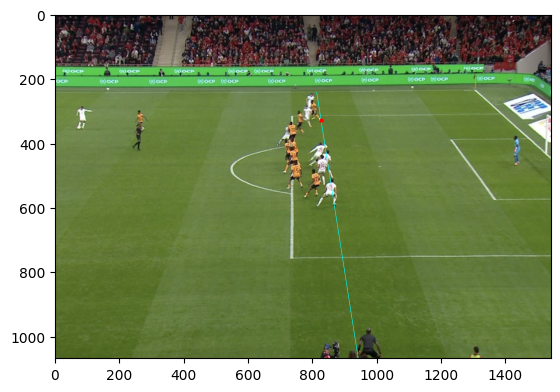

In [ ]:
u1, v1, _ = pixel_pie
u2, v2, _ = segundo_punto

fuera_de_juego = cv2.imread('Archivos/futbol/test-fuera-de-juego.png')
fuera_de_juego = cv2.cvtColor(fuera_de_juego, cv2.COLOR_BGR2RGB)
plt.imshow(fuera_de_juego)

m = (v2 - v1) / (u2 - u1)
b = v1 - m * u1
alto_img, ancho_img = fuera_de_juego.shape[0], fuera_de_juego.shape[1]

v_fin = alto_img - 1
u_fin = u2 + (v_fin - v2) / m

plt.scatter(u1,v1, color="red", s=4, zorder=5)

plt.plot([u2, u_fin], [v2, v_fin], color="cyan", linewidth=0.4)

plt.xlim(0, ancho_img)
plt.ylim(alto_img, 0)

plt.show()

# PODRIAMOS MARCAR EN LA CANCHA LOS PUNTOS DE REFERENCIA ELEGIDOS, ASI COMO EL PARALELO AL PUNTO ROJO

Trazamos la linea de offside, marcamos con un punto rojo el apoyo del pie del jugador del otro equipo sobre ella.
Se puede ver que al menos dos jugadores del equipo blanco están adelantados: El de abajo de todo tiene casi medio cuerpo adelantado, y hay otro que tiene la pierna adelantada. Hay otro que está sobre la linea, pero parece ser que está habilitado ya tiene en brazo adelantado unicamente

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [ ]:
df = pd.read_csv('Archivos/salguero/world_img_pts.csv', sep=";")
display(df)
display(df.shape)
data = df.values

,pts,X,Y,Z,u_0,v_0,u_1,v_1,u_2,v_2,u_3,v_3
0,6,-4.0,3,0.0,281,474,255,490,469,581,446,563
1,36,4.0,0,0.0,889,521,1071,577,1147,653,1118,621
2,40,6.5,3,0.1,1139,493,1403,550,1425,625,1396,590
3,41,-5.0,14,0.1,418,385,437,377,627,485,600,466
4,42,-5.0,76,0.1,833,262,997,227,1094,357,1064,331


(5, 12)

Como tenemos únicamente 5 puntos para realizar la calibración, no se puede realizar la de puntos 3D: Vamos a pensar el problema como uno de puntos coplanares. De esta forma se van a tener más que 4 puntos, que es lo necesario para realizar este tipo de calibración.

Al tener varias tomas distintas, podemos aprovechar esta información para calcular distintos Hj para armar la matriz A, y con ella la matriz K. Habiendo obtenido la matriz K, y para una vista Hj determinada, podemos calcular el valor de la pose de la cámara (los parámetros Rj y tj).

In [ ]:
XY = data[:, 1:3]
u = data[:, 4:12:2]
v = data[:, 5:12:2]

In [ ]:
lista_H = []
for i in range(4):
    ui = u[:,i]
    vi = v[:,i]

    objPts = XY
    imgPts = np.column_stack((ui, vi))

    Q = obtenerQ2d(imgPts, objPts)
    Hj = resolver2D(Q)
    lista_H.append(Hj)

A = armarA(lista_H)
K = calcularMatrizK2D(A).T
print(K)

[[  2782.7801  17702.8087 804474.7902]
 [     0.        213.0557  41679.4551]
 [     0.          0.          1.    ]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

In [ ]:
puntos_primera_imagen = np.loadtxt('Archivos/salguero/gs_10_09_point_correspondences_v5.txt',delimiter='	')

En este caso todos los z valen 0, asi que nuevamente se usa el modelo de puntos coplanares.

In [ ]:
XY, uv = (
    puntos_primera_imagen[1:3,:],
    puntos_primera_imagen[4:,:],

)

XY = XY.T
uv = uv.T

print(XY.shape)
print(uv.shape)

(51, 2)
(51, 2)


Calculamos la matriz Hj específica para esta toma, y se aprovecha el calculo de los parámetros intrínsecos (K) en el item anterior para estimar Rj y tj.

In [ ]:
Q = obtenerQ2d(uv,XY)
Hj = resolver2D(Q)
Rj,tj = obtenerPose2D(Hj, K)

Para proyectar tenemos que usar la homografía con las coords del mundo real. Tomamos XY, que tiene tamaño 51x2, le agregamos una tercera columna de unos, que representa la tercera coord de cada punto, y trasponemos. Esto es porque necesitamos que los puntos o las matrices que sean transformados por H, deben tener 3 filas (H tiene 3 columnas)

In [ ]:
XY_con_unos_traspuesta = np.column_stack((XY, np.ones(51))).T
uv_calculados_trasp = multiplicarMatrices(Hj,XY_con_unos_traspuesta)
uv_calculados = uv_calculados_trasp.T
uv_calculados = (uv_calculados / uv_calculados[:, -1:])[:,0:2]
uv_calculados.shape

(51, 2)

Proyectamos los puntos u,v reales y los calculados con la homografía para ver si la transformación es precisa:

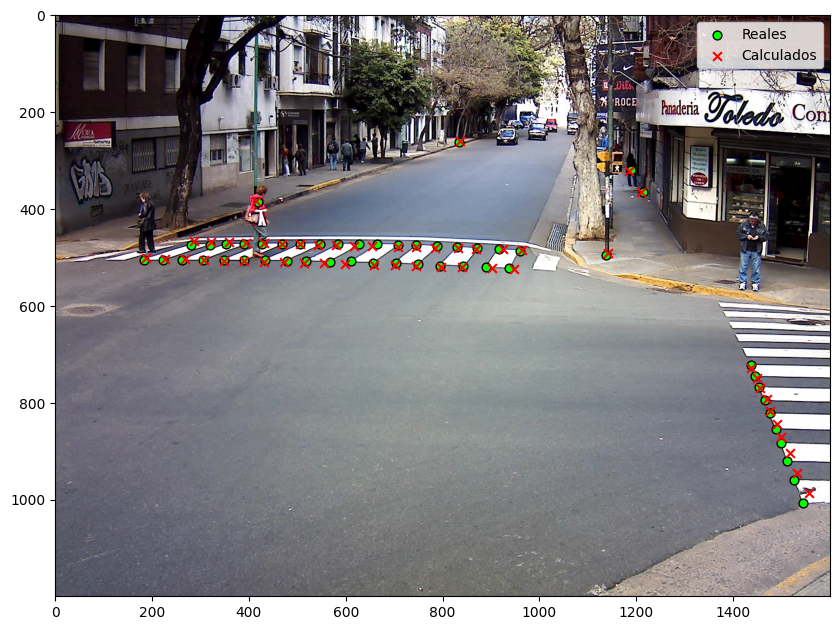

In [ ]:
u_real = uv[:,0]
v_real = uv[:,1]
u_calc = uv_calculados[:,0]
v_calc = uv_calculados[:,1]

imagen_salguero = cv2.imread('Archivos/salguero/img_10_18_47_351.jpg')
imagen_salguero = cv2.cvtColor(imagen_salguero, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(imagen_salguero)

plt.scatter(u_real, v_real, c='lime', label='Reales', s=40, edgecolors='black')

plt.scatter(u_calc, v_calc, c='red', marker='x', label='Calculados', s=40)

plt.legend()
plt.show()

A excepción de algunos puntos, la mayoría de las aproximaciones se parecen bastante a los originales, por lo que la homografía es precisa.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

# GRAFICAR LOS PUNTOS DE REFERENCIA TOMADOS DE LAS 6 IMÁGENES

Tenemos 46 tomas, y todas tienen la misma posición de la cámara, y comparten el parámetro intrínseco. Elegimos tratarla como se fuera una única imagen que tiene distintos puntos.

El segundo final es el 52.546, y el inicial el 47,351. El lapso es de 5,195 segundos. Vamos a usar 6 tomas distribuidas de forma uniforme entre la primera y la ultima para tener un frame cada un segundo aproximadamente, ya que se asume que la separación temporal entre una toma y la siguiente es similar para todas.

Se eligen las imágenes 1,10,19,28,37,46.

Im1: img_10_18_47_351.jpg

Im10: img_10_18_48_350.jpg

Im19: img_10_18_49_582.jpg

Im28: img_10_18_50_534.jpg

Im37: img_10_18_51_563.jpg

Im46: img_10_18_52_546.jpg


In [ ]:
señora_px = np.array([[418,501],[544,495],[695,490],[814,490],[909,489],[989,489]])
taxi_px = np.array([[933,267],[900,283],[835,307],[756,350],[612,419],[299,577]])
camioneta_px = np.array([[995,258],[988,270],[972,288],[941,317],[891,361],[788,445]])
segundos = np.array([47.351,48.350,49.582,50.534,51.563,52.546])

Nuevamente los u,v se seleccionaron mediante Paint.

En el b se calculó la pose de la cámara para la imagen img_10_18_47_351.jpg, que es la misma que la primera de estas 6. Por lo tanto ya se tiene K,Rj y tj para esa imagen y las otras 5.

Se utiliza esta información para construir H, y pasar de las coordenadas en pantalla a las coordenadas reales, así calculamos las velocidades.
Las mismas serán entre los intervalos 1-10, 10-19, 19-28, 28-37, 37-46. Cada una se va a calcular como la norma 2 de (xf,yf)-(xi,yf) (la variación de la distancia), y dividimos por el segundo final menos el segundo inicial. Vamos a tomar la velocidad que se pide en la consigna como el promedio de estas 5 velocidades.

In [ ]:
np.set_printoptions(suppress=True, precision=10)

v_señora = obtener_velocidad_kmh(señora_px, Hj, segundos)
v_taxi = obtener_velocidad_kmh(taxi_px, Hj, segundos)
v_camioneta = obtener_velocidad_kmh(camioneta_px, Hj, segundos)

Graficamos el promedio de velocidades entre 5 intervalos equiespaciados de todas las imágenes

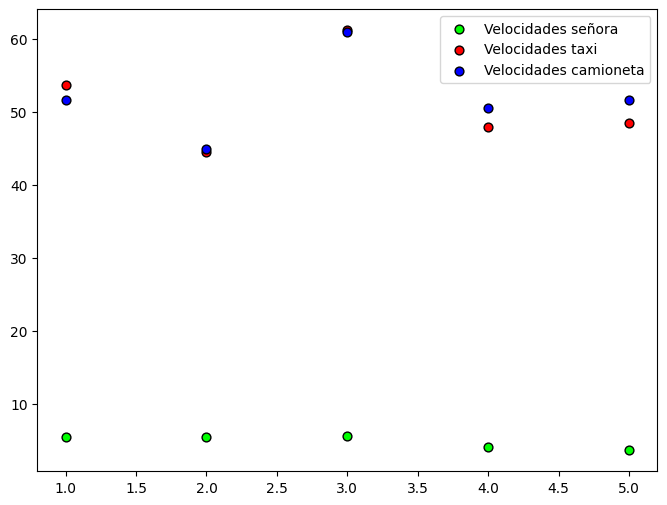

In [ ]:
intervalos_tiempo = np.arange(1,6)

plt.figure(figsize=(8, 6))

plt.scatter(intervalos_tiempo,v_señora, c='lime', label='Velocidades señora', s=40, edgecolors='black')
plt.scatter(intervalos_tiempo,v_taxi, c='red', label='Velocidades taxi', s=40, edgecolors='black')
plt.scatter(intervalos_tiempo,v_camioneta, c='blue', label='Velocidades camioneta', s=40, edgecolors='black')
plt.legend()
plt.show()

In [ ]:
datos = {
    "señora": v_señora,
    "taxi": v_taxi,
    "camioneta": v_camioneta
}

for objeto_persona, velocidades in datos.items():
    promedio = np.mean(velocidades)
    desvio = np.std(velocidades)
    desvio_porcentual = (desvio / promedio) * 100

    print(f"Velocidad minima {objeto_persona}: {np.min(velocidades):.2f} km/h")
    print(f"Velocidad maxima {objeto_persona}: {np.max(velocidades):.2f} km/h")
    print(f"Velocidad promedio {objeto_persona}: {promedio:.2f} km/h")
    print(f"Desvio estandar {objeto_persona}: {desvio:.2f} km/h ({desvio_porcentual:.2f}% del promedio)\n")

Velocidad minima señora: 3.64 km/h
Velocidad maxima señora: 5.56 km/h
Velocidad promedio señora: 4.86 km/h
Desvio estandar señora: 0.81 km/h (16.57% del promedio)

Velocidad minima taxi: 44.58 km/h
Velocidad maxima taxi: 61.22 km/h
Velocidad promedio taxi: 51.21 km/h
Desvio estandar taxi: 5.81 km/h (11.34% del promedio)

Velocidad minima camioneta: 44.99 km/h
Velocidad maxima camioneta: 61.00 km/h
Velocidad promedio camioneta: 51.98 km/h
Desvio estandar camioneta: 5.15 km/h (9.90% del promedio)



Nuevamente aclaramos que estos datos son estimaciones con unos pocos datos de todo el conjunto; no son literalmente el minimo, el maximo y el promedio. Usamos el desvio estandar ya que es una medida que nos permite ver qué tanto se alejan los datos de la media. Puede ocurrir que para valores chicos o grandes, no se llegue a apreciar qué representa este valor. Por eso tomamos el desvío estandar porcentual.

La conclusión que sacamos es que las velocidades son razonables.

Que una persona mayor camine a 5km/h en promedio, una velocidad baja, es lógico.

Las velocidades promedio de los vehículos, alrededor de 50km/h, pueden resultar elevadas para una calle en CABA, siendo el límite 40km/h. Pero analizando los resultados, se tiene que 50km/h son aproximadamente 14m/s, que en 5 segundos, lo que dura el intervalo completo aproximadamente, serían unos 70 metros recorridos. Viendo las imágenes, desde la primera a la última, el taxi comenzó entre el principio y la mitad de la cuadra, y despues de los 5 segundos finalizó ya cruzando la senda peatonal. Como las cuadras tienen una longitud aproximada de 100 metros, es esperable que esa distancia sean 70 metros. Este análisis es análogo para la camioneta, ya que arrancó desde unos metros atras que el taxi y finalizó altras.

### Ejercicio 6 - Aterrizaje suave
Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$.

a)

Para calcular la pose elegimos cinco puntos de la H: el centro y cuatro esquinas. Identificamos sus coordenadas en píxeles en la imagen y les asignamos sus correspondientes coordenadas reales en metros.

In [ ]:
centro_real = (0.0, 0.0, 0.0)
sup_izq_real = (-0.175, 0.3, 0.0)
sup_der_real = (0.175, 0.3, 0.0)
inf_der_real = (0.175, -0.3, 0.0)
inf_izq_real = (-0.175, -0.3, 0.0)

puntos_reales = np.array([
    centro_real,
    sup_izq_real,
    sup_der_real,
    inf_der_real,
    inf_izq_real
])

centro_px = (526, 1007)
sup_izq_px = (402, 1097)
sup_der_px = (392, 944)
inf_der_px = (644, 913)
inf_izq_px = (656, 1061)

puntos_px = np.array([
    centro_px,
    sup_izq_px,
    sup_der_px,
    inf_der_px,
    inf_izq_px
])

# Cargamos la matriz de parametros intrinsecos
K = np.loadtxt("Archivos/heli/K.csv", delimiter=";")

b)

Para recuperar la pose de la cámara, comenzamos con una aproximación de proyección ortográfica escalada, suponiendo que todos los puntos tienen aproximadamente la misma profundidad.

Construimos los vectores relativos al punto de referencia y resolvemos dos sistemas lineales por mínimos cuadrados, obteniendo $I_0$ y $J_0$.

Como los puntos son coplanares, estos vectores no determinan una solución única. Para completarlos, utilizamos el vector normal al plano:

$$I = I_0 + \lambda n, \qquad J = J_0 + \mu n$$

Calculamos $\lambda$ y $\mu$ imponiendo que los vectores resultantes sean perpendiculares y tengan igual norma:

$$I \cdot J = 0, \qquad \|I\|^2 = \|J\|^2$$

Esto permite obtener las dos soluciones posibles, correspondientes a los signos opuestos de $\lambda$ y $\mu$.

In [ ]:
# Parametros intrinsecos de la camara
fx = K[0, 0]
fy = K[1, 1]
cu = K[0, 2]
cv = K[1, 2]

u_centrado = puntos_px[:, 0] - cu
v_centrado = (puntos_px[:, 1] - cv) * fx / fy

M0 = puntos_reales[0]
m0 = np.array([u_centrado[0], v_centrado[0]])

# Construimos los vectores relativos en el plano
A = (puntos_reales[1:] - M0)[:, :2]

# Calculamos la pseudoinversa para resolver por minimos cuadrados
At = A.T
A_pinv = multiplicarMatrices(
    inversa(multiplicarMatrices(At, A)), At
)

# Aproximacion inicial: epsilon = 0
b_u = u_centrado[1:] - u_centrado[0]
b_v = v_centrado[1:] - v_centrado[0]

I_xy = calcularAx(A_pinv, b_u)
J_xy = calcularAx(A_pinv, b_v)

I0 = np.array([I_xy[0], I_xy[1], 0.0])
J0 = np.array([J_xy[0], J_xy[1], 0.0])

lamb, mu = calculoLambdaMu(I0, J0)

print("I0:", I0)
print("J0:", J0)
print("lambda:", lamb)
print("mu:", mu)

I0: [ -31.4285714286 -421.6666666667    0.          ]
J0: [-426.2618486515   55.3479532164    0.          ]
lambda: 115.61293556835668
mu: 85.99025648021194


c)

A partir de los vectores $I$ y $J$ calculados anteriormente, recuperamos la profundidad del punto de referencia:

$$Z_0 = \frac{f}{\|I\|}$$

Normalizamos los vectores para obtener los dos primeros ejes de la cámara y calculamos el tercero mediante el producto vectorial:

$$i = \frac{I}{\|I\|}, \qquad
j = \frac{J}{\|J\|}, \qquad
k = i \times j$$

Estos vectores forman las filas de la matriz de rotación $R$.

Para obtener la traslación, recuperamos la posición del punto de referencia en las coordenadas de la cámara y despejamos $t$ de:

$$M_{0,\text{cam}} = R M_{0,\text{real}} + t$$

Como el problema coplanar admite dos soluciones, calculamos ambas poses.

In [ ]:
# Vector normal al plano de la H
normal_plano = np.array([0.0, 0.0, 1.0])

# Primera solucion
I_mas = I0 + lamb * normal_plano
J_mas = J0 + mu * normal_plano

# Segunda solucion
I_menos = I0 - lamb * normal_plano
J_menos = J0 - mu * normal_plano

In [ ]:
# Primer solucion
i_mas, j_mas, k_mas, Z0_mas, R_mas, t_mas = calcularSalidaPOSIT(
    I_mas, J_mas, fx, m0, M0
)

#segunda solucion
i_menos, j_menos, k_menos, Z0_menos, R_menos, t_menos = calcularSalidaPOSIT(
    I_menos, J_menos, fx, m0, M0
)

print("PRIMER SOLUCION")
print("i:", i_mas)
print("j:", j_mas)
print("k:", k_mas)
print("Z0:", Z0_mas)
print("R:\n", R_mas)
print("t:", t_mas)

print("SEGUNDA SOLUCION")
print("i:", i_menos)
print("j:", j_menos)
print("k:", k_menos)
print("Z0:", Z0_menos)
print("R:\n", R_menos)
print("t:", t_menos)

PRIMER SOLUCION
i: [-0.0716962874 -0.9619251888  0.2637414898]
j: [-0.9724079271  0.1262622696  0.1961648863]
k: [-0.2219965443 -0.2424000214 -0.9444362149]
Z0: 4.318169620435109
R:
 [[-0.0716962874 -0.9619251888  0.2637414898]
 [-0.9724079271  0.1262622696  0.1961648863]
 [-0.2219965443 -0.2424000214 -0.9444362149]]
t: [-0.6695455563  0.8853434964  4.3181696204]
SEGUNDA SOLUCION
i: [-0.0716962874 -0.9619251888 -0.2637414898]
j: [-0.9724079271  0.1262622696 -0.1961648863]
k: [ 0.2219965443  0.2424000214 -0.9444362149]
Z0: 4.318169620435109
R:
 [[-0.0716962874 -0.9619251888 -0.2637414898]
 [-0.9724079271  0.1262622696 -0.1961648863]
 [ 0.2219965443  0.2424000214 -0.9444362149]]
t: [-0.6695455563  0.8853434964  4.3181696204]


In [ ]:
# Comprobamos que las matrices de rotacion sean ortogonales
error_R_mas = multiplicarMatrices(R_mas, R_mas.T) - np.eye(3)
error_R_menos = multiplicarMatrices(R_menos, R_menos.T) - np.eye(3)

print("Error de ortogonalidad, primera solucion:",
      np.max(np.abs(error_R_mas)))

print("Error de ortogonalidad, segunda solucion:",
      np.max(np.abs(error_R_menos)))

Error de ortogonalidad, primera solucion: 2.220446049250313e-16
Error de ortogonalidad, segunda solucion: 2.220446049250313e-16


d)

Para evaluar una pose, transformamos los puntos reales al sistema de coordenadas de la cámara mediante $R$ y $t$.

Una proyección es válida cuando el punto está delante de la cámara, es decir, cuando su coordenada de profundidad satisface $Z>0$.

Para los puntos válidos, calculamos sus proyecciones sobre la imagen utilizando la matriz intrínseca $K$ y las comparamos con las posiciones observadas.

El error de reproyección se mide mediante:

$$RMS = \sqrt{\frac{1}{n}\sum_{p=1}^{n}
\left[(u_p-\hat u_p)^2+(v_p-\hat v_p)^2\right]}$$

Evaluamos las dos soluciones anteriores. Si alguna deja puntos detrás de la cámara, la descartamos. Entre las soluciones factibles, preferimos la que tenga menor RMS.

In [ ]:
validas_mas, rms_mas = evaluarPose(
    R_mas, t_mas, puntos_reales, puntos_px, K
)

validas_menos, rms_menos = evaluarPose(
    R_menos, t_menos, puntos_reales, puntos_px, K
)

print("PRIMERA SOLUCION")
print("Proyecciones validas:", validas_mas)
print("RMS:", rms_mas)

print("\nSEGUNDA SOLUCION")
print("Proyecciones validas:", validas_menos)
print("RMS:", rms_menos)

PRIMERA SOLUCION
Proyecciones validas: 5
RMS: 8.948979147969064

SEGUNDA SOLUCION
Proyecciones validas: 5
RMS: 10.156562834139303


e)

Aplicamos POSIT utilizando los cinco puntos seleccionados en el ítem a).

El algoritmo comienza suponiendo que todos los puntos tienen aproximadamente la misma profundidad. En cada iteración:

1. Corrige las coordenadas utilizando los factores de perspectiva.
2. Resuelve los sistemas lineales para obtener nuevos vectores $I$ y $J$.
3. Recupera las dos poses posibles.
4. Descarta las poses que tengan puntos detrás de la cámara y selecciona la de menor RMS.
5. Actualiza los factores de perspectiva para la siguiente iteración.

El procedimiento termina cuando se alcanza el máximo de iteraciones o cuando la mejora en el RMS es menor que la tolerancia establecida.

Conservamos la mejor pose encontrada durante el proceso.

In [ ]:
# Parametros de convergencia
MaxIt = 100
atol = 1e-8

R_estimada, t_estimada = aplicarPOSIT(
    puntos_reales, puntos_px, K, MaxIt, atol
)

validas, rms = evaluarPose(
    R_estimada, t_estimada, puntos_reales, puntos_px, K
)

print("Matriz de rotacion estimada:")
print(R_estimada)

print("\nVector de traslacion estimado (metros):")
print(t_estimada)

print("\nProyecciones validas:", validas, "de", len(puntos_reales))
print("RMS final:", rms, "pixeles")

Matriz de rotacion estimada:
[[-0.0823809538 -0.9489631038  0.3044378526]
 [-0.9961758644  0.0694888527 -0.0529617468]
 [ 0.0291037065 -0.3076366802 -0.9510586981]]

Vector de traslacion estimado (metros):
[-0.6933090496  0.9167660845  4.471429983 ]

Proyecciones validas: 5 de 5
RMS final: 3.3675762616989653 pixeles


Comprobación visual

Para verificar la estimación, proyectamos nuevamente los cinco puntos reales utilizando la matriz de rotación y el vector de traslación obtenidos.

Representamos sobre la imagen original los puntos observados y los reproyectados. Cuanto más próximas estén ambas posiciones, menor será el error de reproyección.

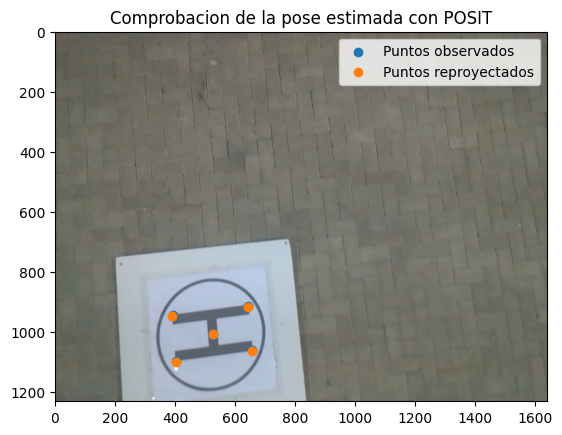

In [ ]:
imagen = cv2.imread("Archivos/heli/row_00248.png")

puntos_reproyectados = np.zeros((len(puntos_reales), 2))

for p in range(len(puntos_reales)):
    punto_cam = calcularAx(R_estimada, puntos_reales[p]) + t_estimada
    pixel_homog = calcularAx(K, punto_cam)

    puntos_reproyectados[p] = pixel_homog[:2] / pixel_homog[2]

# Comparamos los puntos observados con los reproyectados
plt.figure()
plt.imshow(imagen[:, :, ::-1])

plt.scatter(
    puntos_px[:, 0], puntos_px[:, 1],
    label="Puntos observados"
)

plt.scatter(
    puntos_reproyectados[:, 0], puntos_reproyectados[:, 1],
    label="Puntos reproyectados"
)

plt.title("Comprobacion de la pose estimada con POSIT")
plt.legend()
plt.show()

f)

Buscamos una nueva pose en la cual la cámara quede centrada sobre la letra H y su eje óptico sea perpendicular al plano del suelo.

Como tomamos el origen del sistema de coordenadas reales en el centro de la H, la posición objetivo de la cámara debe tener coordenadas:

$$C_{\text{objetivo}}=(0,0,h)$$

donde $h$ es la altura de la cámara. Conservamos la altura estimada mediante POSIT.

Para orientar la cámara hacia el suelo y mantener la parte superior de la H hacia arriba en la imagen, elegimos:

$$R_{\text{objetivo}}=
\begin{pmatrix}
1&0&0\\
0&-1&0\\
0&0&-1
\end{pmatrix}$$

La transformación desde las coordenadas reales a las coordenadas de la cámara es:

$$X_{\text{cam}}=R X_{\text{real}}+t$$

Por lo tanto, la traslación objetivo se obtiene mediante:

$$t_{\text{objetivo}}=-R_{\text{objetivo}}C_{\text{objetivo}}$$

Calculamos la pose objetivo y la comparamos con la pose estimada para determinar el desplazamiento necesario.

In [ ]:

R_objetivo, t_objetivo = obtenerPoseObjetivo(
    R_estimada, t_estimada
)

centro_actual = -calcularAx(R_estimada.T, t_estimada)

centro_objetivo = -calcularAx(R_objetivo.T, t_objetivo)

desplazamiento = centro_objetivo - centro_actual

print("Posicion actual de la camara (metros):")
print(centro_actual)

print("\nPosicion objetivo (metros):")
print(centro_objetivo)

print("\nDesplazamiento necesario (metros):")
print(desplazamiento)

print("\nMatriz R objetivo:")
print(R_objetivo)

print("\nVector t objetivo:")
print(t_objetivo)

Posicion actual de la camara (metros):
[0.7260095999 0.6539461446 4.5122154299]

Posicion objetivo (metros):
[-0.           -0.            4.5122154299]

Desplazamiento necesario (metros):
[-0.7260095999 -0.6539461446  0.          ]

Matriz R objetivo:
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0. -1.]]

Vector t objetivo:
[-0.           -0.            4.5122154299]



Comprobamos que la nueva pose proyecte el centro de la H sobre el punto principal de la cámara y que las esquinas superiores aparezcan por encima de las inferiores en la imagen.

De esta manera verificamos que la cámara está centrada sobre la H y que su orientación corresponde a la indicada por el punto blanco.

In [ ]:
# Proyectamos los puntos de la H con la pose objetivo
puntos_objetivo_px = np.zeros((len(puntos_reales), 2))
profundidades_objetivo = np.zeros(len(puntos_reales))

for p in range(len(puntos_reales)):
    punto_cam = calcularAx(R_objetivo, puntos_reales[p]) + t_objetivo

    profundidades_objetivo[p] = punto_cam[2]

    pixel_homog = calcularAx(K, punto_cam)
    puntos_objetivo_px[p] = pixel_homog[:2] / pixel_homog[2]

print("Centro de la H:", puntos_objetivo_px[0])
print("Esquina superior izquierda:", puntos_objetivo_px[1])
print("Esquina superior derecha:", puntos_objetivo_px[2])
print("Esquina inferior derecha:", puntos_objetivo_px[3])
print("Esquina inferior izquierda:", puntos_objetivo_px[4])

print("\nTodos los puntos delante de la camara:",
      np.all(profundidades_objetivo > 0))

print("Centro correctamente proyectado:",
      np.max(np.abs(puntos_objetivo_px[0] - K[:2, 2])) < 1e-8)

print("Esquinas superiores por encima de las inferiores:",
      np.max(puntos_objetivo_px[1:3, 1]) <
      np.min(puntos_objetivo_px[3:5, 1]))

Centro de la H: [819.5 615.5]
Esquina superior izquierda: [746.0865060863 488.5446254396]
Esquina superior derecha: [892.9134939137 488.5446254396]
Esquina inferior derecha: [892.9134939137 742.4553745604]
Esquina inferior izquierda: [746.0865060863 742.4553745604]

Todos los puntos delante de la camara: True
Centro correctamente proyectado: True
Esquinas superiores por encima de las inferiores: True


**Conclusión**

A partir de la pose obtenida mediante POSIT, calculamos la posición y orientación que debería alcanzar el drone para quedar exactamente sobre la mira H, mirando perpendicularmente hacia el suelo.

La posición objetivo es aproximadamente $(0,0,4.51)$ metros en el sistema de coordenadas de la H.

La matriz de rotación elegida permite que la cámara mire hacia abajo y conserve la orientación indicada por el punto blanco.

La traslación y rotación calculadas describen la pose geométrica deseada. Para un aterrizaje real, el drone debería desplazarse y orientarse progresivamente hasta alcanzarla.